# HRDScout — Grouped and Nested Grouped Cross-Validation

HRDScout is trained on a synthetic matrix in which each retained PCAWG tumour is
multinomially downsampled many times, so a single tumour contributes ~21 correlated rows.
Under a random `StratifiedKFold` split, replicates of the same tumour fall in both the
training and held-out partitions, and the reported metrics may be inflated by
tumour-level memorisation rather than reflecting generalisation to unseen tumours.

## What this notebook does

1. **Reproduces the original evaluation** — random `StratifiedKFold` over the 15,435-row synthetic matrix — as the baseline to compare against.
2. **Quantifies the leakage** — shows that under random folds, replicates of *the same* original tumour are split across train and test in essentially every fold.
3. **Re-runs validation with grouped CV** — `StratifiedGroupKFold` keyed on the **original PCAWG tumour**, so *all* downsampled replicates of a tumour are confined to a single fold. No replicate of a test tumour is ever seen in training.
4. **Adds nested grouped CV** for the per-ratio operating-point (threshold) selection, so the FPR ≤ 0.02 threshold is chosen on inner training folds and never on the data it is scored against.
5. **Reports the identical metric panel** (AUC, PR-AUC, TPR, Precision, F1, MCC per down-sampling ratio) under random vs. grouped vs. nested-grouped CV, side by side.

The grouping key is recovered from the synthetic-sample index, which has the form `{original_tumor}_{ratio}_{iteration}` (e.g. `PD3989a_10_1`).

> **Input data.** This notebook consumes `output/LABELED_synthetic_training_matrix.csv`,
> which is excluded from version control because it is derived from restricted PCAWG data.
> Place the file in `output/` before executing. Cell outputs below are preserved from the
> run reported in the manuscript.


## 0. Imports and paths

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (
    cross_val_predict, StratifiedKFold, StratifiedGroupKFold,
)
from sklearn.metrics import (
    roc_curve, auc,
    precision_recall_curve, average_precision_score,
    f1_score, matthews_corrcoef, confusion_matrix,
)

warnings.filterwarnings("ignore", category=UserWarning)

mpl.rcParams.update({
    'pdf.fonttype': 42,
    'font.family': 'Sans',
    'font.size': 9,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.linewidth': 0.4,
    'xtick.major.width': 0.4,
    'ytick.major.width': 0.4,
    'xtick.direction': 'out',
    'ytick.direction': 'out',
})

BASE         = os.path.dirname(os.path.abspath("__file__"))
OUTDIR       = os.path.join(BASE, "output")
LABELED_PATH = os.path.join(OUTDIR, "LABELED_synthetic_training_matrix.csv")

# ── Exact hyperparameters from the original training run ──────────────────
RF_KWARGS  = dict(n_estimators=100, random_state=41)
CV_FOLDS   = 10
TARGET_FPR = 0.02
MAX_RATIO  = 100   # only ratios ≤ 100 appear in the paper table
SEED       = 42

print("Configuration:")
print(f"  RF: {RF_KWARGS}")
print(f"  CV folds: {CV_FOLDS}")
print(f"  Operating point: FPR \u2264 {TARGET_FPR}")
print(f"  Ratios reported: \u2264 {MAX_RATIO}")

Configuration:
  RF: {'n_estimators': 100, 'random_state': 41}
  CV folds: 10
  Operating point: FPR ≤ 0.02
  Ratios reported: ≤ 100


## 1. Load the labeled synthetic matrix and recover the tumor-of-origin

Each row is a multinomially downsampled replicate. The index encodes
`{original_tumor}_{ratio}_{iteration}`; the **original tumor** is everything before the
last two underscore-delimited fields and is used as the grouping key for grouped CV.

In [2]:
labeled_matrix = pd.read_csv(LABELED_PATH, index_col=0)

X = labeled_matrix.drop(columns=["HRDetect_binary"])
y = labeled_matrix["HRDetect_binary"]
FEATURE_COLS = list(X.columns)

# Parse index → (tumor, ratio, iteration)
parsed   = [idx.rsplit("_", 2) for idx in labeled_matrix.index]
groups   = np.array([p[0] for p in parsed])              # original PCAWG tumor
suffix   = np.array([int(p[1]) for p in parsed])          # downsampling ratio
iters    = np.array([p[2] for p in parsed])               # replicate iteration

n_groups       = len(np.unique(groups))
reps_per_group = pd.Series(groups).value_counts()

# Sanity check: label must be constant within an original tumor
label_consistency = (pd.DataFrame({'g': groups, 'y': y.values})
                       .groupby('g')['y'].nunique())
assert (label_consistency == 1).all(), "Label varies within a tumor group!"
group_label = (pd.DataFrame({'g': groups, 'y': y.values})
                 .groupby('g')['y'].first())

print(f"Synthetic matrix       : {X.shape[0]:,} replicates \u00d7 {X.shape[1]} features")
print(f"Original PCAWG tumors   : {n_groups}")
print(f"  HRDetect-high tumors  : {int(group_label.sum())}")
print(f"  HRDetect-low  tumors  : {int((group_label==0).sum())}")
print(f"Replicates per tumor    : min={reps_per_group.min()}, "
      f"median={int(reps_per_group.median())}, max={reps_per_group.max()}")
print(f"Down-sampling ratios    : {sorted(np.unique(suffix).tolist())}")
print(f"Label consistency check : PASS (each tumor has a single HRDetect label)")

Synthetic matrix       : 15,435 replicates × 179 features
Original PCAWG tumors   : 735
  HRDetect-high tumors  : 273
  HRDetect-low  tumors  : 462
Replicates per tumor    : min=21, median=21, max=21
Down-sampling ratios    : [10, 20, 30, 40, 50, 100, 120, 150]
Label consistency check : PASS (each tumor has a single HRDetect label)


## 2. Quantify the leakage under random folds

Under the original random `StratifiedKFold`, a tumor's ~21 replicates are scattered across
folds independently. We measure, for the original random split, what fraction of **test**
tumors also have at least one replicate in the **training** partition of the same fold —
i.e. direct train/test leakage at the tumor level.

In [3]:
def leakage_audit(cv, X, y, groups, label):
    """Fraction of test tumors that also appear in the training partition."""
    frac_leaked, n_test_tumors = [], []
    for tr, te in cv.split(X, y, groups):
        tr_groups = set(groups[tr])
        te_groups = set(groups[te])
        leaked = te_groups & tr_groups
        frac_leaked.append(len(leaked) / max(len(te_groups), 1))
        n_test_tumors.append(len(te_groups))
    frac_leaked = np.array(frac_leaked)
    print(f"{label}")
    print(f"  test tumors per fold (mean)     : {np.mean(n_test_tumors):.1f}")
    print(f"  test tumors also seen in train  : {frac_leaked.mean():.1%} "
          f"(range {frac_leaked.min():.1%}\u2013{frac_leaked.max():.1%})")
    return frac_leaked

random_cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
grouped_cv = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)

print("="*64)
_ = leakage_audit(random_cv,  X, y, groups, "Random StratifiedKFold (original method):")
print()
_ = leakage_audit(grouped_cv, X, y, groups, "StratifiedGroupKFold (grouped by tumor):")
print("="*64)
print("\nUnder random folds, essentially every test tumor also contributes replicates\n"
      "to training in the same fold \u2192 the classifier can memorize tumor-specific\n"
      "signal. Grouped CV drives this to exactly 0%.")

Random StratifiedKFold (original method):
  test tumors per fold (mean)     : 651.3
  test tumors also seen in train  : 100.0% (range 100.0%–100.0%)

StratifiedGroupKFold (grouped by tumor):
  test tumors per fold (mean)     : 73.5
  test tumors also seen in train  : 0.0% (range 0.0%–0.0%)

Under random folds, essentially every test tumor also contributes replicates
to training in the same fold → the classifier can memorize tumor-specific
signal. Grouped CV drives this to exactly 0%.


## 3. Held-out cross-validated probabilities: random vs. grouped

`cross_val_predict` returns the out-of-fold probability for every replicate. We compute it
twice with identical RF hyperparameters — once with the original random folds, once with
tumor-grouped folds — so every downstream metric is directly comparable.

> **Runtime:** ~3–5 minutes per scheme (100 trees × 10 folds × 15,435 samples).

In [4]:
def oof_probabilities(cv, groups=None, tag=""):
    rf = RandomForestClassifier(**RF_KWARGS)
    print(f"Running {CV_FOLDS}-fold cross_val_predict ({tag}) \u2026")
    proba = cross_val_predict(
        rf, X, y,
        cv=cv, groups=groups,
        method="predict_proba", n_jobs=-1,
    )[:, 1]
    print(f"  done. proba range [{proba.min():.3f}, {proba.max():.3f}]")
    return proba

proba_random  = oof_probabilities(random_cv,  groups=None,   tag="random folds")
proba_grouped = oof_probabilities(grouped_cv, groups=groups, tag="grouped by tumor")

Running 10-fold cross_val_predict (random folds) …
  done. proba range [0.000, 1.000]
Running 10-fold cross_val_predict (grouped by tumor) …
  done. proba range [0.000, 1.000]


## 4. Per-ratio metric panel (threshold chosen on the same OOF scores)

This reproduces the exact metric definitions of the original performance table — PR-AUC,
ROC-AUC, and the operating-point metrics (TPR, Precision, F1, MCC) at the strictest
threshold with FPR ≤ 0.02 — and applies them to **both** the random and grouped OOF scores.

In [5]:
def per_ratio_metrics(y_all, proba, suffix_arr, target_fpr=0.02, max_ratio=100):
    """Per-down-sampling-ratio metric panel from held-out probabilities."""
    ratios = sorted([s for s in np.unique(suffix_arr).tolist() if s <= max_ratio])
    rows = []
    for s in ratios:
        mask  = (suffix_arr == s)
        y_sub = np.asarray(y_all)[mask]
        p_sub = proba[mask]

        pr_auc = average_precision_score(y_sub, p_sub)
        fpr, tpr, thr = roc_curve(y_sub, p_sub)
        roc_auc = auc(fpr, tpr)

        eligible = np.where(fpr <= target_fpr)[0]
        op_idx   = int(eligible[-1]) if len(eligible) else 0
        op_thr   = float(thr[op_idx])
        y_hat    = (p_sub >= op_thr).astype(int)

        tn, fp, fn, tp = confusion_matrix(y_sub, y_hat).ravel()
        prec_at = tp / (tp + fp) if (tp + fp) else float("nan")
        rec_at  = tp / (tp + fn) if (tp + fn) else float("nan")
        rows.append({
            "downsampling_ratio":    s,
            "simulated_sensitivity": f"{100/s:.1f}%",
            "threshold":             round(op_thr, 3),
            "AUC":                   round(roc_auc, 3),
            "PR_AUC":                round(pr_auc, 3),
            "TPR_recall":            round(rec_at, 3),
            "precision":             round(prec_at, 3),
            "F1":                    round(f1_score(y_sub, y_hat, zero_division=0), 3),
            "MCC":                   round(matthews_corrcoef(y_sub, y_hat), 3),
        })
    return pd.DataFrame(rows)

metrics_random  = per_ratio_metrics(y, proba_random,  suffix, TARGET_FPR, MAX_RATIO)
metrics_grouped = per_ratio_metrics(y, proba_grouped, suffix, TARGET_FPR, MAX_RATIO)

print("Random StratifiedKFold (original, potential leakage):")
print(metrics_random.to_string(index=False))
print("\nStratifiedGroupKFold (grouped by original tumor):")
print(metrics_grouped.to_string(index=False))

Random StratifiedKFold (original, potential leakage):
 downsampling_ratio simulated_sensitivity  threshold   AUC  PR_AUC  TPR_recall  precision    F1   MCC
                 10                 10.0%       0.64 0.994   0.990       0.921      0.967 0.943 0.911
                 20                  5.0%       0.60 0.989   0.983       0.896      0.967 0.930 0.893
                 30                  3.3%       0.60 0.986   0.980       0.877      0.964 0.919 0.876
                 40                  2.5%       0.63 0.987   0.979       0.841      0.966 0.899 0.851
                 50                  2.0%       0.59 0.986   0.978       0.830      0.968 0.893 0.844
                100                  1.0%       0.52 0.975   0.965       0.800      0.960 0.873 0.816

StratifiedGroupKFold (grouped by original tumor):
 downsampling_ratio simulated_sensitivity  threshold   AUC  PR_AUC  TPR_recall  precision    F1   MCC
                 10                 10.0%       0.65 0.992   0.988       0.913 

## 5. Nested grouped CV for honest threshold selection

The metrics in Section 4 still pick the FPR ≤ 0.02 threshold on the *same* held-out scores
they are evaluated on. To remove that last optimism, we run **nested grouped CV**:

- **Outer loop** — `StratifiedGroupKFold`, grouped by tumor. The outer-test replicates are
  never used for training *or* threshold selection.
- **Inner loop** — within each outer-train partition, a second grouped `cross_val_predict`
  produces inner OOF scores from which the per-ratio FPR ≤ 0.02 threshold is selected.
- A fresh RF is then fit on the full outer-train partition, scored on outer-test, and the
  inner-selected per-ratio thresholds are applied to those outer-test scores.

Outer-test scores are pooled across folds for the AUC/PR-AUC; confusion counts are pooled
across folds for the operating-point metrics.

> **Runtime:** ~15–30 minutes (10 outer fits + 10 × inner CV).

In [6]:
def select_thresholds_per_ratio(y_in, p_in, suffix_in, ratios, target_fpr):
    """Strictest FPR<=target threshold per ratio, from inner-fold OOF scores."""
    thr_map = {}
    for s in ratios:
        m = (suffix_in == s)
        if m.sum() == 0 or len(np.unique(y_in[m])) < 2:
            thr_map[s] = 0.5
            continue
        fpr, tpr, thr = roc_curve(y_in[m], p_in[m])
        elig = np.where(fpr <= target_fpr)[0]
        thr_map[s] = float(thr[int(elig[-1])]) if len(elig) else float(thr[0])
    return thr_map


ratios = sorted([s for s in np.unique(suffix).tolist() if s <= MAX_RATIO])
Xv, yv = X.values, y.values

outer_cv = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)

# Pooled outer-test OOF scores (honest) + per-ratio pooled confusion counts
nested_proba = np.full(len(yv), np.nan)
conf = {s: dict(tp=0, fp=0, tn=0, fn=0) for s in ratios}

for k, (tr, te) in enumerate(outer_cv.split(Xv, yv, groups), start=1):
    print(f"Outer fold {k}/{CV_FOLDS} \u2026", flush=True)
    # Inner grouped CV on the outer-train partition → threshold selection
    inner_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + k)
    inner_proba = cross_val_predict(
        RandomForestClassifier(**RF_KWARGS),
        Xv[tr], yv[tr], cv=inner_cv, groups=groups[tr],
        method="predict_proba", n_jobs=-1,
    )[:, 1]
    thr_map = select_thresholds_per_ratio(
        yv[tr], inner_proba, suffix[tr], ratios, TARGET_FPR)

    # Fit on full outer-train, score outer-test
    rf = RandomForestClassifier(**RF_KWARGS).fit(Xv[tr], yv[tr])
    p_te = rf.predict_proba(Xv[te])[:, 1]
    nested_proba[te] = p_te

    # Apply inner-selected per-ratio thresholds to outer-test
    for s in ratios:
        m = (suffix[te] == s)
        if m.sum() == 0:
            continue
        y_hat = (p_te[m] >= thr_map[s]).astype(int)
        yt = yv[te][m]
        conf[s]["tp"] += int(((y_hat == 1) & (yt == 1)).sum())
        conf[s]["fp"] += int(((y_hat == 1) & (yt == 0)).sum())
        conf[s]["tn"] += int(((y_hat == 0) & (yt == 0)).sum())
        conf[s]["fn"] += int(((y_hat == 0) & (yt == 1)).sum())

print("Nested grouped CV complete.")

Outer fold 1/10 …
Outer fold 2/10 …
Outer fold 3/10 …
Outer fold 4/10 …
Outer fold 5/10 …
Outer fold 6/10 …
Outer fold 7/10 …
Outer fold 8/10 …
Outer fold 9/10 …
Outer fold 10/10 …
Nested grouped CV complete.


In [7]:
# Assemble the nested-grouped metric panel from pooled outer-test results
nested_rows = []
for s in ratios:
    m = (suffix == s)
    y_sub, p_sub = yv[m], nested_proba[m]
    pr_auc  = average_precision_score(y_sub, p_sub)
    fpr, tpr, _ = roc_curve(y_sub, p_sub)
    roc_auc = auc(fpr, tpr)
    c = conf[s]
    tp, fp, tn, fn = c["tp"], c["fp"], c["tn"], c["fn"]
    prec = tp / (tp + fp) if (tp + fp) else float("nan")
    rec  = tp / (tp + fn) if (tp + fn) else float("nan")
    f1   = (2 * prec * rec / (prec + rec)) if (prec and rec and prec + rec) else 0.0
    denom = np.sqrt((tp+fp)*(tp+fn)*(tn+fp)*(tn+fn))
    mcc  = ((tp*tn - fp*fn) / denom) if denom else 0.0
    nested_rows.append({
        "downsampling_ratio":    s,
        "simulated_sensitivity": f"{100/s:.1f}%",
        "AUC":                   round(roc_auc, 3),
        "PR_AUC":                round(pr_auc, 3),
        "TPR_recall":            round(rec, 3),
        "precision":             round(prec, 3),
        "F1":                    round(f1, 3),
        "MCC":                   round(mcc, 3),
    })
metrics_nested = pd.DataFrame(nested_rows)
print("Nested grouped CV (grouped folds + inner-selected thresholds):")
print(metrics_nested.to_string(index=False))

Nested grouped CV (grouped folds + inner-selected thresholds):
 downsampling_ratio simulated_sensitivity   AUC  PR_AUC  TPR_recall  precision    F1   MCC
                 10                 10.0% 0.992   0.988       0.913      0.965 0.939 0.905
                 20                  5.0% 0.989   0.984       0.885      0.965 0.924 0.883
                 30                  3.3% 0.985   0.978       0.866      0.963 0.912 0.868
                 40                  2.5% 0.985   0.975       0.842      0.958 0.897 0.846
                 50                  2.0% 0.985   0.977       0.842      0.964 0.899 0.851
                100                  1.0% 0.973   0.962       0.808      0.957 0.876 0.819


## 6. Side-by-side comparison

The decisive question: how much do the headline metrics move when leakage is
removed? Small deltas mean the original numbers were **not** driven by tumor memorization.

In [8]:
key = "downsampling_ratio"
merged = (metrics_random.add_suffix("_rand").rename(columns={f"{key}_rand": key})
          .merge(metrics_grouped.add_suffix("_grp").rename(columns={f"{key}_grp": key}), on=key)
          .merge(metrics_nested.add_suffix("_nest").rename(columns={f"{key}_nest": key}), on=key))

compare = pd.DataFrame({
    "Ratio":          merged[key].astype(int).astype(str) + "\u00d7",
    "AUC rand":       merged["AUC_rand"],
    "AUC grp":        merged["AUC_grp"],
    "AUC nest":       merged["AUC_nest"],
    "PR-AUC rand":    merged["PR_AUC_rand"],
    "PR-AUC grp":     merged["PR_AUC_grp"],
    "PR-AUC nest":    merged["PR_AUC_nest"],
    "F1 rand":        merged["F1_rand"],
    "F1 grp":         merged["F1_grp"],
    "F1 nest":        merged["F1_nest"],
    "MCC rand":       merged["MCC_rand"],
    "MCC grp":        merged["MCC_grp"],
    "MCC nest":       merged["MCC_nest"],
})
print(compare.to_string(index=False))

print("\nMean absolute change vs. original random CV:")
for metric in ["AUC", "PR_AUC", "F1", "MCC"]:
    d_grp  = (merged[f"{metric}_grp"]  - merged[f"{metric}_rand"]).abs().mean()
    d_nest = (merged[f"{metric}_nest"] - merged[f"{metric}_rand"]).abs().mean()
    print(f"  {metric:7s}  grouped \u0394={d_grp:.3f}   nested-grouped \u0394={d_nest:.3f}")

Ratio  AUC rand  AUC grp  AUC nest  PR-AUC rand  PR-AUC grp  PR-AUC nest  F1 rand  F1 grp  F1 nest  MCC rand  MCC grp  MCC nest
  10×     0.994    0.992     0.992        0.990       0.988        0.988    0.943   0.939    0.939     0.911    0.905     0.905
  20×     0.989    0.989     0.989        0.983       0.984        0.984    0.930   0.923    0.924     0.893    0.883     0.883
  30×     0.986    0.985     0.985        0.980       0.978        0.978    0.919   0.910    0.912     0.876    0.865     0.868
  40×     0.987    0.985     0.985        0.979       0.975        0.975    0.899   0.895    0.897     0.851    0.845     0.846
  50×     0.986    0.985     0.985        0.978       0.977        0.977    0.893   0.898    0.899     0.844    0.849     0.851
 100×     0.975    0.973     0.973        0.965       0.962        0.962    0.873   0.871    0.876     0.816    0.815     0.819

Mean absolute change vs. original random CV:
  AUC      grouped Δ=0.001   nested-grouped Δ=0.001
  PR_A

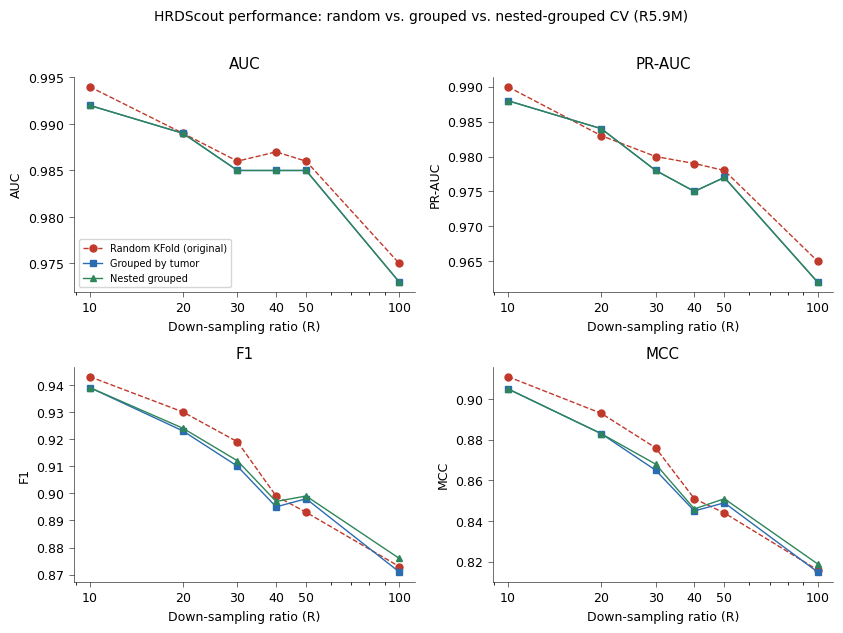

Saved: grouped_CV_comparison.pdf


In [9]:
# ── Figure: AUC / PR-AUC / F1 / MCC vs ratio, random vs grouped vs nested ─────
fig, axes = plt.subplots(2, 2, figsize=(8.5, 6.4))
panels = [("AUC", "AUC"), ("PR_AUC", "PR-AUC"),
          ("F1", "F1"), ("MCC", "MCC")]
x = merged[key].values
styles = [("_rand", "Random KFold (original)", "#c0392b", "o", "--"),
          ("_grp",  "Grouped by tumor",        "#2b6cb0", "s", "-"),
          ("_nest", "Nested grouped",          "#2f855a", "^", "-")]
for ax, (col, title) in zip(axes.ravel(), panels):
    for sfx, lab, c, mk, ls in styles:
        ax.plot(x, merged[f"{col}{sfx}"], marker=mk, linestyle=ls,
                color=c, linewidth=1, markersize=5, label=lab)
    ax.set_xlabel("Down-sampling ratio (R)")
    ax.set_ylabel(title)
    ax.set_title(title)
    ax.set_xscale("log")
    ax.set_xticks(x)
    ax.get_xaxis().set_major_formatter(mpl.ticker.ScalarFormatter())
axes[0, 0].legend(fontsize=7, loc="lower left")
fig.suptitle("HRDScout performance: random vs. grouped vs. nested-grouped CV",
             fontsize=10)
plt.tight_layout(rect=[0, 0, 1, 0.97])
fig.savefig(os.path.join(OUTDIR, "grouped_CV_comparison.pdf"), bbox_inches="tight")
plt.show()
print("Saved: grouped_CV_comparison.pdf")

In [10]:
# Persist the comparison tables
metrics_random.to_csv(os.path.join(OUTDIR, "metrics_randomCV.csv"), index=False)
metrics_grouped.to_csv(os.path.join(OUTDIR, "metrics_groupedCV.csv"), index=False)
metrics_nested.to_csv(os.path.join(OUTDIR, "metrics_nestedGroupedCV.csv"), index=False)
compare.to_csv(os.path.join(OUTDIR, "metrics_comparison.csv"), index=False)
print("Saved 4 CSVs to output/ (random, grouped, nested-grouped, comparison).")

Saved 4 CSVs to output/ (random, grouped, nested-grouped, comparison).
